# Sentiment Labelled Sentences — разведочный анализ


In [1]:
from pathlib import Path
import sys, os
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import display, Image

def show_table(name, n=20):
    display(pd.read_csv(ROOT / 'reports/tables' / f'{name}.csv').head(n))

def show_figure(name):
    display(Image(filename=str(ROOT / 'reports/figures' / f'{name}.png')))


In [2]:
from src.coursework.sentiment import main
summary = main()
summary

Sentiment complete: 3000 raw; 2972 clean


{'rows': 3000,
 'class_counts': {0: 1500, 1: 1500},
 'by_source': {0: {'amazon': 500, 'imdb': 500, 'yelp': 500},
  1: {'amazon': 500, 'imdb': 500, 'yelp': 500}},
 'missing': 0,
 'empty': 0,
 'duplicates': {'text': {'groups': 17,
   'rows_in_groups': 34,
   'redundant_rows': 17},
  'normalized': {'groups': 21, 'rows_in_groups': 49, 'redundant_rows': 28}},
 'conflicting_groups': 0,
 'conflicting_rows': 0,
 'clean_rows': 2972,
 'splits': {'train': 2080, 'test': 446, 'validation': 446},
 'multiline_records': 0,
 'unicode_separator_records': 2,
 'svd_explained_variance': np.float64(0.23801672056659617),
 'lengths': {'chars': {'count': 3000.0,
   'mean': 65.27133333333333,
   'std': 44.16356550817677,
   'min': 7.0,
   '1%': 12.0,
   '5%': 17.0,
   '25%': 33.0,
   '50%': 55.5,
   '75%': 88.0,
   '95%': 142.0,
   '99%': 215.0299999999993,
   'max': 479.0},
  'words': {'count': 3000.0,
   'mean': 11.891333333333334,
   'std': 7.955540318721904,
   'min': 1.0,
   '1%': 2.0,
   '5%': 3.0,
   '25

## Структура, кодировка и качество данных

,source,file,encoding,physical_lf_lines,records,header,delimiter,unicode_separator_records
0,amazon,amazon_cells_labelled.txt,utf-8 (strict),1000,1000,False,TAB,0
1,imdb,imdb_labelled.txt,utf-8 (strict),1000,1000,False,TAB,2
2,yelp,yelp_labelled.txt,utf-8 (strict),1000,1000,False,TAB,0


,source,line,kind,text
0,imdb,179,unicode_line_separator,The script is was there a script? \t0
1,imdb,968,unicode_line_separator,Definitely worth seeing it's the sort of thou...


,source,0,1
0,amazon,500,500
1,imdb,500,500
2,yelp,500,500


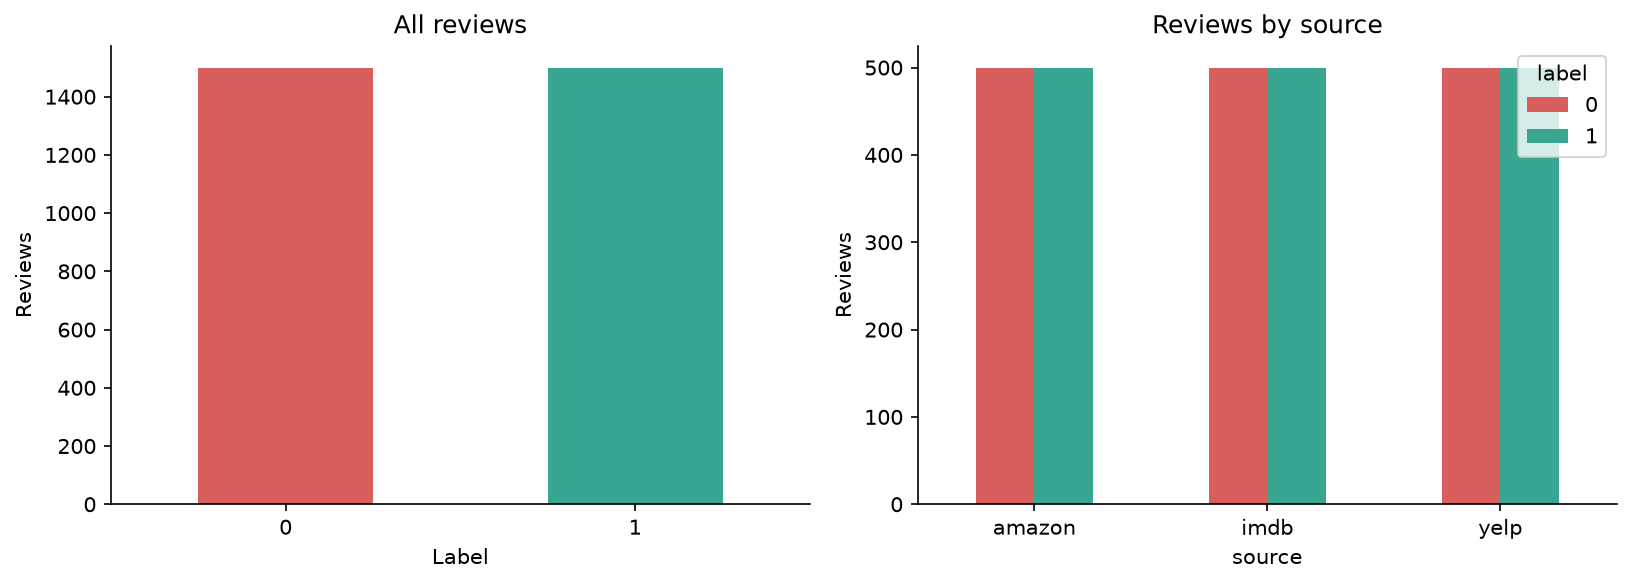

In [3]:
show_table('sentiment_file_structure')
show_table('sentiment_parse_anomalies')
show_table('sentiment_class_counts')
show_figure('sentiment_balance')

In [4]:
summary['duplicates'], summary['missing'], summary['empty'], summary['conflicting_groups']

({'text': {'groups': 17, 'rows_in_groups': 34, 'redundant_rows': 17},
  'normalized': {'groups': 21, 'rows_in_groups': 49, 'redundant_rows': 28}},
 0,
 0,
 0)

In [5]:
show_table('sentiment_duplicates_normalized', 15)

,id,source,line_start,line_end,text,label,normalized,chars,words
0,imdb_0126,imdb,126,126,10/10,1,10 10,7,2
1,imdb_0789,imdb,789,789,10/10,1,10 10,7,2
2,imdb_0627,imdb,627,627,Avoid at all costs.,0,avoid at all costs,21,4
3,imdb_0802,imdb,802,802,Avoid at ALL costs!,0,avoid at all costs,21,4
4,imdb_0091,imdb,91,91,Definitely worth checking out.,1,definitely worth checking out,32,4
5,imdb_0364,imdb,364,364,Definitely worth checking out.,1,definitely worth checking out,32,4
6,amazon_0994,amazon,994,994,disappointed.,0,disappointed,13,1
7,amazon_0464,amazon,464,464,Disappointed!.,0,disappointed,14,1
8,amazon_0749,amazon,749,749,Does not fit.,0,does not fit,13,3
9,amazon_0447,amazon,447,447,Does not fit.,0,does not fit,13,3


## Длины текстов
Символы учитываются в исходном тексте; слова — регулярным выражением с сохранением внутренних апострофов. Наличие пунктуации и хвостовых пробелов отражается на длине в символах.

,Unnamed: 0,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,chars,3000.0,65.271333,44.163566,7.0,12.0,17.0,33.0,55.5,88.0,142.0,215.03,479.0
1,words,3000.0,11.891333,7.955540,1.0,2.0,3.0,6.0,10.0,16.0,26.0,36.00,73.0


,source,level_1,count,mean,std,min,5%,50%,95%,max
0,amazon,chars,1000.0,55.226,34.653482,11.0,13.95,48.0,125.05,149.0
1,amazon,words,1000.0,10.290,6.746363,1.0,2.00,9.0,23.05,30.0
2,imdb,chars,1000.0,82.272,56.286039,7.0,20.00,68.0,187.00,479.0
3,imdb,words,1000.0,14.478,9.737676,1.0,3.00,12.0,33.05,73.0
4,yelp,chars,1000.0,58.316,32.364140,11.0,18.00,51.0,121.00,149.0
5,yelp,words,1000.0,10.906,6.279060,1.0,3.00,10.0,23.00,32.0


,label,level_1,count,mean,std,min,5%,50%,95%,max
0,0,chars,1500.0,64.887333,41.404592,8.0,17.0,56.0,139.05,321.0
1,0,words,1500.0,11.943333,7.646902,1.0,3.0,10.5,25.00,57.0
2,1,chars,1500.0,65.655333,46.770791,7.0,16.0,55.0,147.00,479.0
3,1,words,1500.0,11.839333,8.254874,1.0,3.0,10.0,27.00,73.0


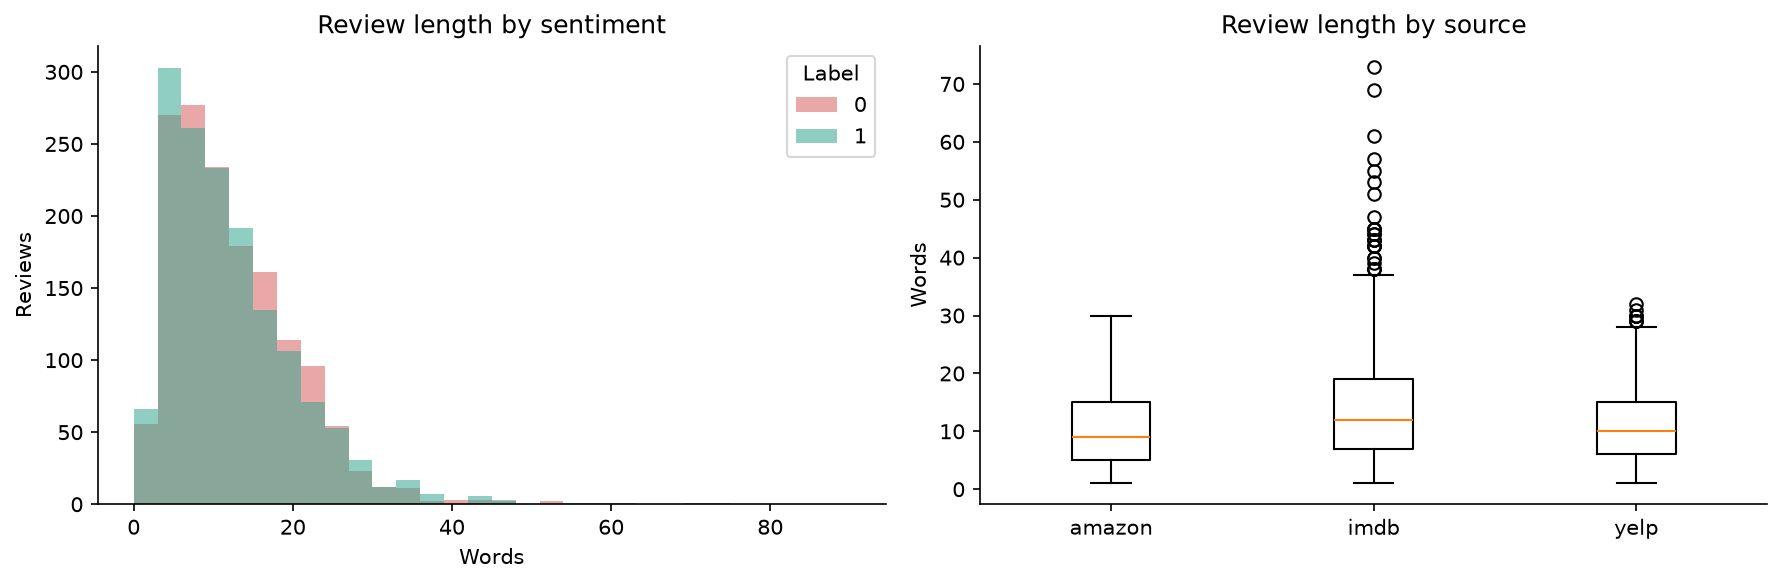

In [6]:
show_table('sentiment_lengths_overall')
show_table('sentiment_lengths_by_source', 40)
show_table('sentiment_lengths_by_label', 40)
show_figure('sentiment_lengths')

## Лексика и различия источников
Частоты — числа употреблений и документная частота после удаления английских стоп-слов. Характерность — логарифм отношения сглаженных относительных частот группы к остальным текстам; на графике минимум 5 документов. Это описательная статистика, а не причинная связь.

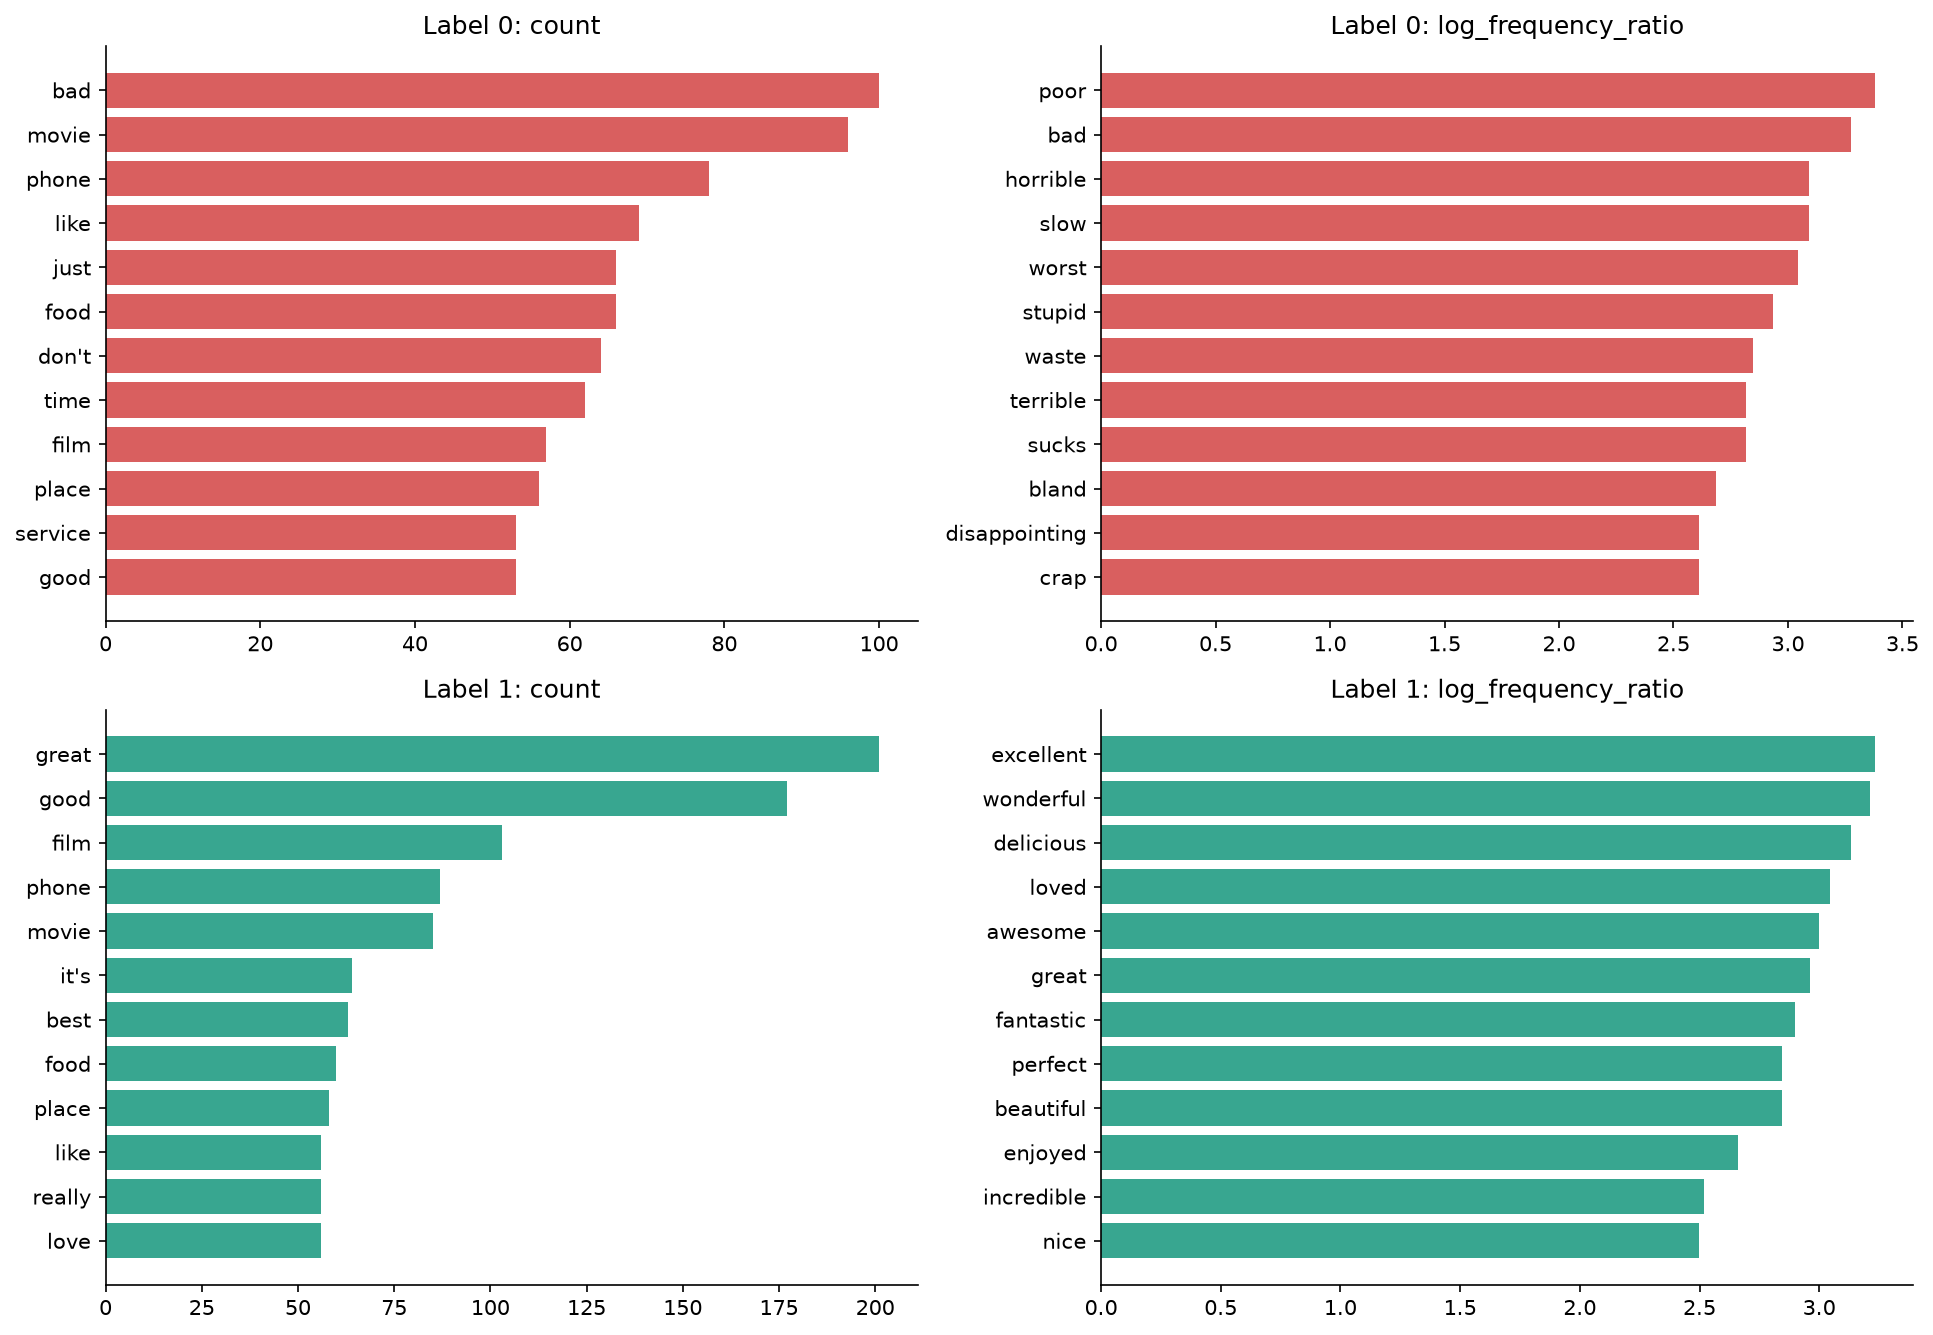

,grouping,group,word,count,document_frequency,log_frequency_ratio
5175,source,amazon,phone,165,156,5.748344
4689,source,amazon,great,99,97,0.523027
4682,source,amazon,good,77,74,-0.043888
5254,source,amazon,product,55,55,3.968560
5281,source,amazon,quality,49,49,1.658007
4730,source,amazon,headset,47,45,4.507557
5871,source,amazon,works,47,46,2.561647
4054,source,amazon,battery,46,45,4.486504
5527,source,amazon,sound,43,40,2.341104
5767,source,amazon,use,41,40,2.176801


,grouping,group,word,count,document_frequency,log_frequency_ratio
7014,source,imdb,movie,181,171,5.555354
6551,source,imdb,film,160,153,5.432751
6001,source,imdb,bad,71,59,1.131505
6798,source,imdb,it's,69,62,0.771201
6823,source,imdb,just,63,62,0.467179
6648,source,imdb,good,58,54,-0.724407
6879,source,imdb,like,48,44,-0.113542
5909,source,imdb,acting,43,43,4.135537
7645,source,imdb,time,43,43,-0.112959
6655,source,imdb,great,41,40,-1.046782


,grouping,group,word,count,document_frequency,log_frequency_ratio
8549,source,yelp,food,126,121,5.451524
9120,source,yelp,place,106,103,3.082941
8614,source,yelp,good,95,91,0.259030
9389,source,yelp,service,85,85,1.883631
8621,source,yelp,great,70,64,-0.078743
8845,source,yelp,like,46,44,0.075458
9611,source,yelp,time,42,42,0.105857
9244,source,yelp,really,36,34,-0.001253
8789,source,yelp,just,35,35,-0.251795
8002,source,yelp,best,30,29,0.149504


In [7]:
show_figure('sentiment_vocabulary')
words = pd.read_csv(ROOT / 'reports/tables/sentiment_word_statistics.csv')
for source in ['amazon', 'imdb', 'yelp']:
    display(words[(words.grouping == 'source') & (words['group'] == source)].nlargest(12, 'count'))

## TF-IDF → SVD(50) → t-SNE
Проекция для разведочного анализа строится по всему корпусу. Она не используется при обучении или оценке. Координаты и расстояния между дальними кластерами не интерпретируются как качество классификатора. Для будущей модели TF-IDF необходимо обучать только на train.

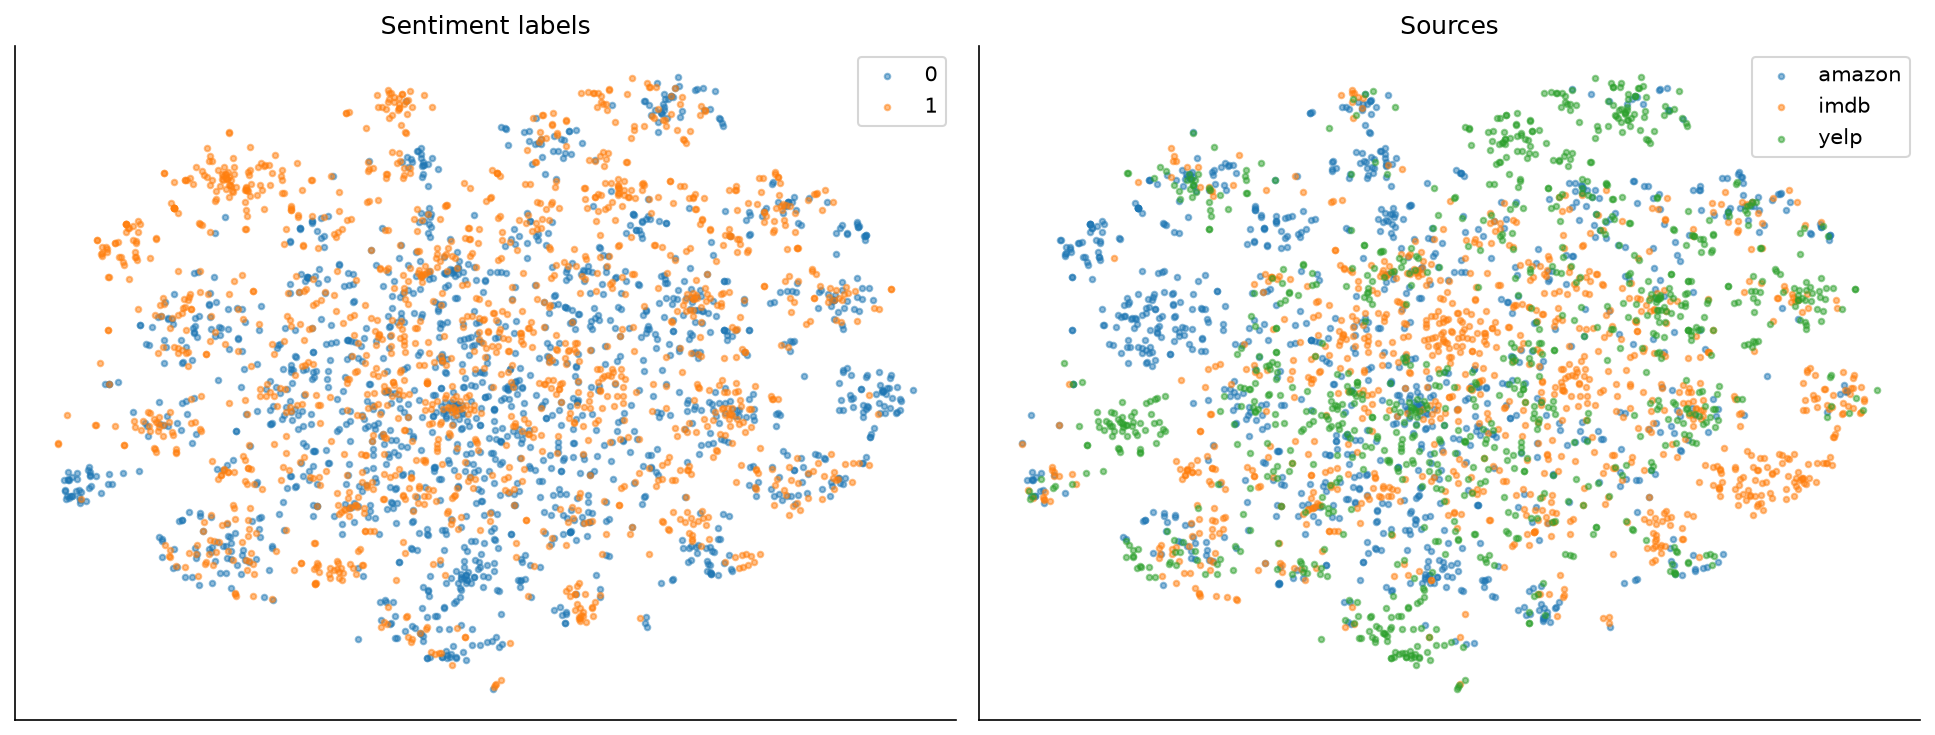

np.float64(0.23801672056659617)

In [8]:
show_figure('sentiment_tsne')
summary['svd_explained_variance']

## Примеры и неоднозначность
Кандидаты с разной полярностью слов и очень короткие отзывы требуют ручного просмотра. Эвристика не проверяет истинность всех меток; отрицание, сарказм и контекст сохраняют неоднозначность.

In [9]:
show_table('sentiment_review_candidates', 60)

,id,source,line_start,line_end,text,label,normalized,chars,words,split,mixed_cues,reason
0,amazon_0744,amazon,744,744,"Bought mainly for the charger, which broke soo...",0,bought mainly for the charger which broke soon...,65,10,validation,False,stratified_sample
1,amazon_0152,amazon,152,152,"Audio Quality is poor, very poor.",0,audio quality is poor very poor,33,6,train,False,stratified_sample
2,amazon_0768,amazon,768,768,I really wanted the Plantronics 510 to be the ...,0,i really wanted the plantronics 510 to be the ...,99,21,train,False,stratified_sample
3,amazon_0593,amazon,593,593,THey are so cool!,1,they are so cool,17,4,validation,False,stratified_sample
4,amazon_0883,amazon,883,883,The only good thing was that it fits comfortab...,1,the only good thing was that it fits comfortab...,63,12,train,False,stratified_sample
5,amazon_0246,amazon,246,246,Worth every penny.,1,worth every penny,18,3,train,False,stratified_sample
6,imdb_0198,imdb,198,198,This movie is BAD.,0,this movie is bad,20,4,validation,False,stratified_sample
7,imdb_0489,imdb,489,489,I particularly remember my senses being assaul...,0,i particularly remember my senses being assaul...,148,24,test,False,stratified_sample
8,imdb_0068,imdb,68,68,There was absolutely no warmth or charm to the...,0,there was absolutely no warmth or charm to the...,72,12,train,False,stratified_sample
9,imdb_0450,imdb,450,450,"I won't say any more - I don't like spoilers, ...",1,i won t say any more i don t like spoilers so ...,118,25,train,False,stratified_sample


## Train / validation / test
70/15/15, стратификация по source × label после удаления нормализованных повторов. Для группы выбирается первый по source/id представитель. Конфликтующие группы исключаются, если обнаружены. CSV всех исходных строк хранит связь с разбиением. Пересечения по нормализованному тексту проверяются assert.

In [10]:
show_table('sentiment_split_balance')
summary['splits'], summary['split_intersections']

,split,source,0,1
0,test,amazon,74,74
1,test,imdb,74,75
2,test,yelp,74,75
3,train,amazon,346,342
4,train,imdb,348,349
5,train,yelp,346,349
6,validation,amazon,74,73
7,validation,imdb,75,74
8,validation,yelp,75,75


({'train': 2080, 'test': 446, 'validation': 446}, 0)

## Правила очистки и ограничения
- Сохранять исходный отзыв, отрицания, апострофы и эмоциональную пунктуацию для моделирования. NFC, casefold, удаление пунктуации и свёртка пробелов служат только ключом дедупликации; для модели достаточно нормализовать пробелы и NEL.
- Применять словари и преобразования обучения только на train; делать аугментации после разбиения и только в train.
- Сбалансированный выбор коротких отзывов без нейтрального класса не отражает реальную долю положительных/отрицательных мнений. Три домена имеют разную лексику; случайное стратифицированное разбиение не оценивает перенос на новый домен.
- Ручная выборочная проверка не доказывает корректность всех 3000 меток. Не менять метки автоматически по ключевым словам.

Итоговые выводы: `reports/EDA_REPORT.md`.